# Financial Toolkit · Demo

Recorrido por la librería de principio a fin:

1. **Ingesta multifuente**: misma salida venga de la API que venga
2. **Descarga de N activos** en una sola llamada, con limpieza automática
3. **PriceSeries**: estadísticos automáticos e indicadores técnicos
4. **Fundamentales**: estados financieros con ratios y alertas
5. **Tipos de interés y macro**: bonos de 4 bancos centrales, FRED y World Bank
6. **Limpieza y validación de inputs**
7. **Cartera**: pesos, operaciones, flujos de caja y métricas
8. **Monte Carlo**
9. **`report()` y `plots_report()`**

Yahoo Finance, los bonos y el World Bank no necesitan API key. FMP, CoinGecko y FRED se usan solo si su clave está en `.env`.

In [1]:
import os
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from dotenv import load_dotenv
from IPython.display import Markdown, display

# Works from examples/ or from the project root, installed or not.
root = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "src" / "financial_toolkit").is_dir())
if str(root / "src") not in sys.path:
    sys.path.insert(0, str(root / "src"))
load_dotenv(root / ".env")

from financial_toolkit import (
    AssetFetcher, CoinGeckoApi, FMPAPI, MacroFetcher, Portfolio, PriceSeries, Stock,
    YahooFinanceAPI, clean_prices, find_outliers,
)

pd.set_option("display.float_format", "{:,.4f}".format)
plt.rcParams["figure.figsize"] = (12, 4)
keys = {name: bool(os.getenv(name)) for name in ("FMP_API_KEY", "COINGECKO_API_KEY", "FRED_API_KEY")}
keys

{'FMP_API_KEY': True, 'COINGECKO_API_KEY': True, 'FRED_API_KEY': True}

## 1. Ingesta multifuente: misma salida, venga de la API que venga

Cada API tiene su extractor, pero todos devuelven los mismos objetos (`Stock`, `Index`, `Cryptocurrency`), cada uno con su `PriceSeries`.

In [2]:
yahoo = YahooFinanceAPI()

apple = yahoo.get_stock("AAPL", period="3y")
sp500 = yahoo.get_index("^GSPC", start="2023-01-01")
bitcoin = yahoo.get_crypto("BTC-USD", period="3y")

for asset in (apple, sp500, bitcoin):
    print(f"{type(asset).__name__:15} {asset.price.close.index[-1].date()}  "
          f"último cierre {asset.price.current_price():>12,.2f}  ({type(asset.price).__name__})")
print("\nEmpresa:", apple.company.name, "·", apple.company.industry, "·", apple.currency)

Stock           2026-11-09  último cierre       349.83  (PriceSeries)
Index           2026-11-09  último cierre     7,520.22  (PriceSeries)
Cryptocurrency  2026-11-09  último cierre    74,909.89  (PriceSeries)

Empresa: Apple Inc. · Consumer Electronics · USD


In [3]:
# The same stock from FMP: same class, same fields, comparable prices.
if keys["FMP_API_KEY"]:
    apple_fmp = FMPAPI(api_key=os.getenv("FMP_API_KEY")).get_stock("AAPL", period="1y")
    both = pd.concat({
        "Yahoo": apple.price.close.tz_localize(None).rename(lambda d: d.normalize()),
        "FMP": apple_fmp.price.close.rename(lambda d: pd.Timestamp(d).tz_localize(None).normalize()),
    }, axis=1).dropna()
    print(type(apple_fmp).__name__, "| mismos campos:", list(vars(apple_fmp)) == list(vars(apple)))
    print(f"Diferencia media de cierre Yahoo vs FMP: {(both['FMP'] / both['Yahoo'] - 1).abs().mean():.4%}")
else:
    print("Sin FMP_API_KEY: se omite la comparación Yahoo vs FMP")

Income statement for AAPL requires a paid FMP subscription


Balance sheet for AAPL requires a paid FMP subscription


Cash flow for AAPL requires a paid FMP subscription
Stock | mismos campos: True
Diferencia media de cierre Yahoo vs FMP: 0.0009%


In [4]:
# The same cryptocurrency from CoinGecko returns the same Cryptocurrency class.
if keys["COINGECKO_API_KEY"]:
    bitcoin_cg = CoinGeckoApi().get_crypto("bitcoin", days=90)
    print(type(bitcoin_cg).__name__, "|", bitcoin_cg.name, "| ranking", bitcoin_cg.market_cap_rank)
    print(bitcoin_cg.tokenomics)
else:
    print("Sin COINGECKO_API_KEY: se omite CoinGecko")

Cryptocurrency | Bitcoin | ranking 1
Tokenomics(circulating_supply=20109909.0, total_supply=20109934.0, max_supply=21000000.0)


## 2. Descarga de N activos en una sola llamada

`AssetFetcher.get_many()` recibe una lista de peticiones (tipo, API, símbolo) y un periodo común. Elige el extractor, recorta al periodo y **limpia cada serie**, guardando un `CleaningReport` por activo.

In [5]:
START, END = "2023-01-03", "2025-10-31"

requests = [
    {"type": "stock", "api": "yfinance", "symbol": "AAPL"},
    {"type": "stock", "api": "yfinance", "symbol": "MSFT"},
    {"type": "stock", "api": "yfinance", "symbol": "SAN"},
    {"type": "stock", "api": "yfinance", "symbol": "IEF"},     # bond ETF: fixed income with a price
    {"type": "crypto", "api": "yfinance", "symbol": "BTC-USD"},
    {"type": "index", "api": "yfinance", "symbol": "^GSPC"},
]
fetcher = AssetFetcher()
aapl, msft, san, ief, btc, gspc = fetcher.get_many(requests, start=START, end=END)

pd.DataFrame({symbol: vars(report) for symbol, report in fetcher.cleaning_reports.items()}).T

There is not available income statement for IEF


There is not available balance sheet for IEF
There is not cashflow for IEF 


,n_input,n_output,invalid_dates,duplicates,missing,timezone,outliers
AAPL,711,711,0,0,0,America/New_York,2
MSFT,711,711,0,0,0,America/New_York,1
SAN,711,711,0,0,0,America/New_York,1
IEF,711,711,0,0,0,America/New_York,0
BTC-USD,1033,1033,0,0,0,UTC,0
^GSPC,711,711,0,0,0,America/New_York,3


## 3. PriceSeries: estadísticos automáticos e indicadores

Media y volatilidad (diarias y anualizadas) se calculan **al crear el objeto**. Además, cada serie trae SMA, EMA, Bollinger, RSI, MACD y drawdown.

In [6]:
pd.DataFrame({
    a.ticker if hasattr(a, "ticker") else a.symbol: {
        "mean_return": a.price.mean_return,
        "volatility": a.price.volatility,
        "periods_per_year": a.price.periods_per_year,
        "annual_return": a.price.annual_return,
        "annual_volatility": a.price.annual_volatility,
        "max_drawdown": a.price.max_drawdown(),
    }
    for a in (aapl, msft, san, ief, btc, gspc)
}).T

,mean_return,volatility,periods_per_year,annual_return,annual_volatility,max_drawdown
AAPL,0.0011,0.0164,251.1143,0.2776,0.2592,-0.3336
MSFT,0.0011,0.0147,251.1143,0.2803,0.2327,-0.2373
SAN,0.0019,0.0193,251.1143,0.4669,0.3066,-0.1989
IEF,0.0001,0.0048,251.1143,0.0342,0.0754,-0.1016
BTC-USD,0.0018,0.0244,365.0000,0.6657,0.4670,-0.2814
^GSPC,0.0008,0.0096,251.1143,0.2057,0.1516,-0.1890


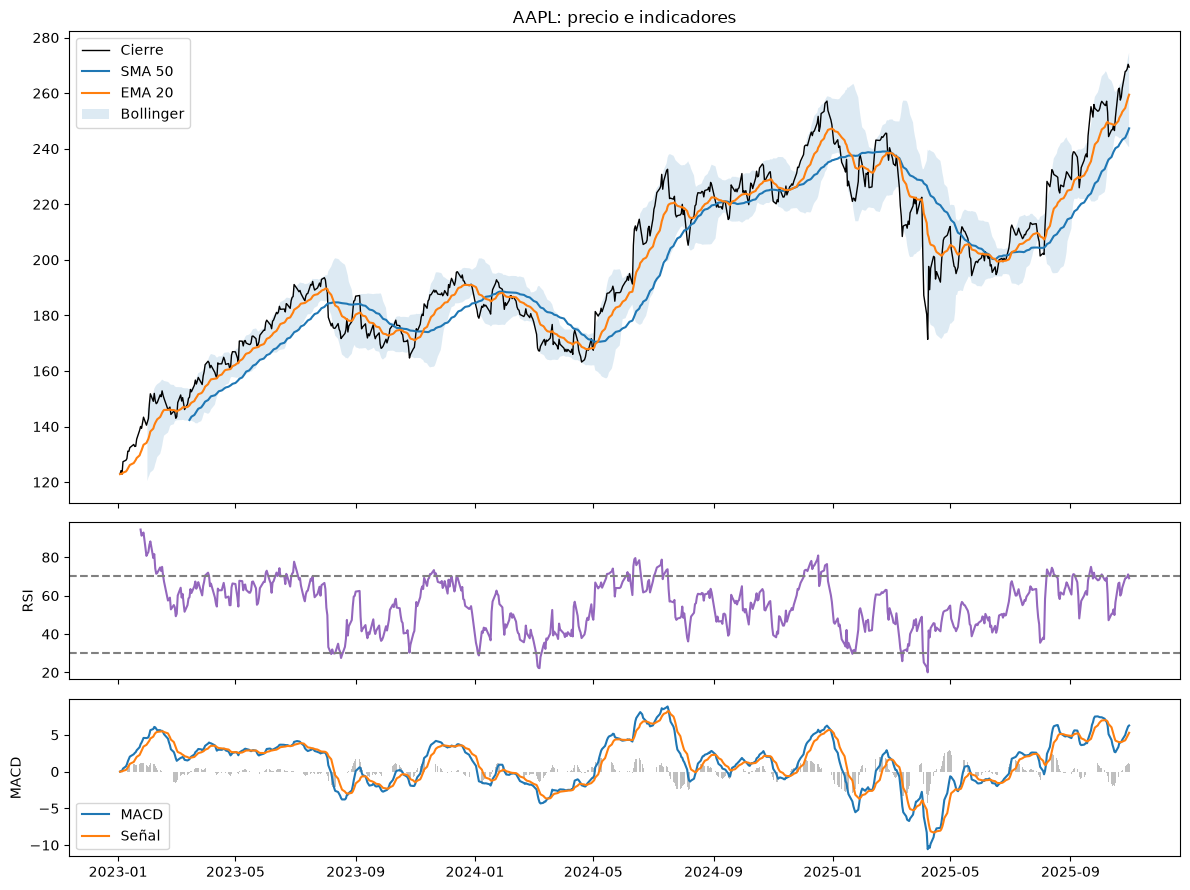

In [7]:
prices = aapl.price
fig, axes = plt.subplots(3, 1, figsize=(12, 9), sharex=True, gridspec_kw={"height_ratios": [3, 1, 1]})

bands = prices.bollinger_bands()
axes[0].plot(prices.close, label="Cierre", color="black", lw=1)
axes[0].plot(prices.sma(50), label="SMA 50")
axes[0].plot(prices.ema(20), label="EMA 20")
axes[0].fill_between(bands.index, bands["Lower"], bands["Upper"], alpha=0.15, label="Bollinger")
axes[0].legend(); axes[0].set_title("AAPL: precio e indicadores")

axes[1].plot(prices.rsi(), color="tab:purple")
axes[1].axhline(70, ls="--", color="grey"); axes[1].axhline(30, ls="--", color="grey")
axes[1].set_ylabel("RSI")

macd = prices.macd()
axes[2].plot(macd["MACD"], label="MACD"); axes[2].plot(macd["Signal"], label="Señal")
axes[2].bar(macd.index, macd["Histogram"], color="grey", alpha=0.5)
axes[2].legend(); axes[2].set_ylabel("MACD")
plt.tight_layout()

## 4. Fundamentales: los tres estados financieros con ratios y alertas

In [8]:
fundamentals = apple.company.fundamentals
display(fundamentals.analyze_income_statement())

,2022,2023,2024,2025,2026
Gross margin percentage,NaN,44.1311,46.2063,46.9052,48.7856
Operating margin percentage,NaN,29.8214,31.5102,31.9708,33.0100
Operating expense to revenue,NaN,14.3097,14.6961,14.9344,15.7756
Consistency (Gross profit - operating expenses = operating income),False,True,True,True,True
Revenue growth,NaN,NaN,2.0220,6.4255,15.0598
Cost of revenue growth,NaN,NaN,-1.7676,5.0430,10.9848
Operating expense growth,NaN,NaN,4.7769,8.1508,21.5411
Operating income growth,NaN,NaN,7.7996,7.9811,18.7997
Net income growth,NaN,NaN,-3.3600,19.4952,18.0029
Interest expense growth,NaN,34.1863,NaN,NaN,NaN


In [9]:
display(fundamentals.analyze_balance_sheet())
display(fundamentals.analyze_cash_flow())

,2022,2023,2024,2025,2026
Debt-to-equity ratio,NaN,1.7875,1.8723,1.3380,0.7147
Current assets weight (%),NaN,40.7184,41.9165,41.1860,42.9756
Inventory weight (%),NaN,1.7956,1.9963,1.5917,3.5944
Net PPE weight (%),NaN,12.3985,12.5158,13.8720,12.8746
Intangible assets weight (%),NaN,NaN,NaN,3.0879,5.0125
Debt-to-liabilities weight (%),NaN,38.2486,34.6164,34.5549,27.3926
Balance sheet consistency,<NA>,True,True,True,True
Negative equity warning,<NA>,False,False,False,False
Inventory change (%),NaN,NaN,15.0845,-21.5207,154.3022
Net PPE change (%),NaN,NaN,4.4950,9.0937,4.5150


,2022,2023,2024,2025,2026
Consistency (CFO + CFI + CFF = Net cash change),False,True,True,True,True
Free cash flow (FCF),NaN,"99,584,000,000.0000","108,807,000,000.0000","98,767,000,000.0000","136,056,000,000.0000"
CAPEX/DA ratio,NaN,0.9514,0.8254,1.0869,0.6735
CAPEX/CFO ratio,NaN,0.0991,0.0799,0.1141,0.0623
Dividend coverage,NaN,6.6279,7.1424,6.4047,8.6544
FCF payout ratio,NaN,0.9296,1.0126,1.0746,0.7505
Net debt issued,0.0000,"-5,923,000,000.0000","-9,958,000,000.0000","-6,451,000,000.0000","-12,396,000,000.0000"
Working capital (%),NaN,-5.9497,3.0874,-22.4251,-10.2400
Other investments,NaN,"14,664,000,000.0000","12,382,000,000.0000","27,910,000,000.0000","-8,239,000,000.0000"
Reconstructed CFO,NaN,"101,937,000,000.0000","108,832,000,000.0000","98,708,000,000.0000","130,740,000,000.0000"


## 5. Tipos de interés y macroeconomía

Los bonos se descargan de **4 bancos centrales** con formatos distintos (XML, CSV) y `BondNormalizer` los convierte en el mismo objeto `Bond`.

,source,current %,change (bps),volatility
US10Y,us_treasury,4.1100,16.0000,0.2289
EU10Y,bce,2.6782,56.5121,0.1716
JP10Y,japan,1.6700,102.1000,0.3159
UK10Y,uk,4.4234,70.4400,0.2750


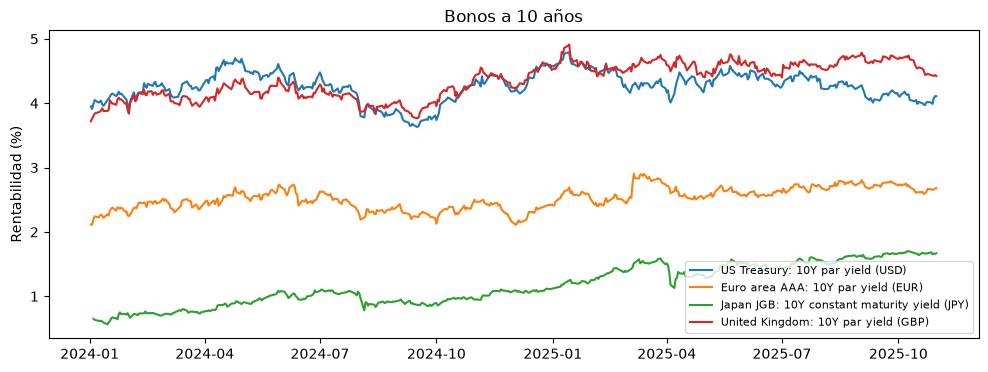

In [10]:
bond_requests = [
    {"type": "bond", "api": "us_treasury", "symbol": "US10Y"},
    {"type": "bond", "api": "bce", "symbol": "EU10Y"},
    {"type": "bond", "api": "japan", "symbol": "JP10Y"},
    {"type": "bond", "api": "uk", "symbol": "UK10Y"},
]
import time

bonds = []
for request in bond_requests:
    # Public servers fail now and then (e.g. a 504 from the ECB): retry, and
    # if a source is still down, go on without it.
    for attempt in range(3):
        try:
            bonds += fetcher.get_many([request], start="2024-01-01", end=END)
            break
        except Exception as error:
            if attempt == 2:
                print(f"{request['api']} no disponible ahora: {type(error).__name__}")
            else:
                time.sleep(10)

fig, ax = plt.subplots()
for bond in bonds:
    ax.plot(bond.series.ytm, label=bond.name)
ax.set_ylabel("Rentabilidad (%)"); ax.set_title("Bonos a 10 años"); ax.legend(fontsize=8)

pd.DataFrame({b.ticker: {"source": b.source, "current %": b.series.current_yield(),
                         "change (bps)": b.series.yield_change_total_bps(),
                         "volatility": b.series.yield_volatility()} for b in bonds}).T

Inflation, consumer prices (annual % growth) | Y | media ES: 2.03


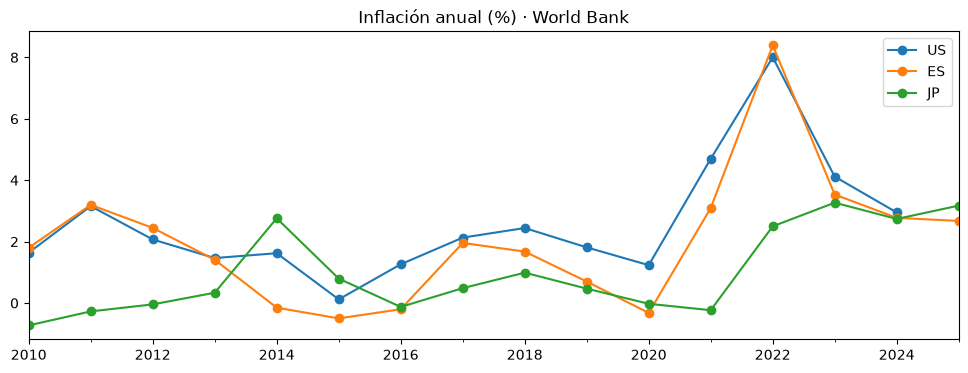

In [11]:
macro = MacroFetcher()
inflation = {
    country: macro.get_macro_series("FP.CPI.TOTL.ZG", source="WB", country=country, start="2010-01-01")
    for country in ("US", "ES", "JP")
}
print(inflation["ES"].name, "|", inflation["ES"].frequency, "| media ES:", round(inflation["ES"].mean, 2))
pd.DataFrame({c: s.data for c, s in inflation.items()}).plot(title="Inflación anual (%) · World Bank", marker="o");

In [12]:
# FRED: 3-month Treasury bill, later used as the risk-free rate.
risk_free = 0.0
if keys["FRED_API_KEY"]:
    bill = macro.get_macro_series("DTB3", source="FRED", start=START, end=END)
    risk_free = float(bill.data.dropna().iloc[-1]) / 100
    print(bill.name, f"→ risk-free = {risk_free:.2%}")
else:
    print("Sin FRED_API_KEY: risk-free = 0")

3-Month Treasury Bill Secondary Market Rate, Discount Basis → risk-free = 3.73%


## 6. Limpieza y validación de inputs

**Limpieza**: las filas con cierre inválido se eliminan (no se rellenan) y, si superan el 5%, la serie se rechaza. Los outliers se **cuentan pero no se tocan**: en finanzas suelen ser reales.

In [13]:
dates = pd.bdate_range("2024-01-01", periods=250)
close = pd.Series(100 * np.exp(np.cumsum(np.random.default_rng(0).normal(0, 0.01, 250))), index=dates)
dirty = close.copy()
dirty.iloc[[10, 50]] = np.nan        # missing closes
dirty.iloc[120:] *= 0.5              # unadjusted 2:1 split -> outlier
dirty_series = PriceSeries(date=dates, open=dirty, high=dirty, low=dirty, close=dirty, volume=None)

clean, report = clean_prices(dirty_series)
print(report)
print("Outlier detectado (se conserva):", find_outliers(clean.close).round(3).to_dict())

too_dirty = dirty.copy(); too_dirty.iloc[::10] = np.nan   # 10% missing
try:
    clean_prices(PriceSeries(date=dates, open=too_dirty, high=too_dirty, low=too_dirty, close=too_dirty, volume=None))
except ValueError as error:
    print("\nRechazada:", error)

CleaningReport(n_input=250, n_output=248, invalid_dates=0, duplicates=0, missing=2, timezone=None, outliers=1)
Outlier detectado (se conserva): {Timestamp('2024-06-17 00:00:00'): -0.685}

Rechazada: missing closes must be at most 5%, got 10.00% (25 of 250)


**Validación estricta**: la cartera solo acepta activos con precio, en USD y con datos coherentes. Mejor un error claro que métricas falsas.

In [14]:
san_eur = yahoo.get_stock("SAN.MC", period="1y")
cases = {
    "Bono (rentabilidad, no precio)": lambda: Portfolio.from_weights([bonds[0]], [1.0], 10_000, START),
    "Acción en EUR": lambda: Portfolio.from_weights([san_eur], [1.0], 10_000, san_eur.price.close.index[0]),
    "Peso no numérico": lambda: Portfolio.from_weights([aapl], ["50%"], 10_000, START),
    "Capital negativo": lambda: Portfolio.from_weights([aapl], [1.0], -10_000, START),
    "Peso duplicado": lambda: Portfolio.from_weights([aapl, aapl], [0.5, 0.5], 10_000, START),
    "Simulaciones = 0": lambda: Portfolio.from_weights([aapl], [1.0], 10_000, START).monte_carlo(0),
}
for name, case in cases.items():
    try:
        case()
        print(f"{name:32} -> aceptado")
    except (TypeError, ValueError) as error:
        print(f"{name:32} -> {type(error).__name__}: {error}")

Bono (rentabilidad, no precio)   -> TypeError: Invalid asset type
Acción en EUR                    -> ValueError: Convert asset prices to USD before trading
Peso no numérico                 -> ValueError: could not convert string to float: '50%'
Capital negativo                 -> ValueError: Capital must be positive and finite
Peso duplicado                   -> ValueError: Provide assets with unique identifiers
Simulaciones = 0                 -> ValueError: n_simulations must be a positive integer, got 0


## 7. La cartera

Los pesos **no se guardan, se calculan** con los precios de cada día: derivan con el mercado, como en una cartera real.

In [15]:
weights = {"AAPL": 0.25, "MSFT": 0.25, "SAN": 0.15, "IEF": 0.20, "BTC-USD": 0.15}
portfolio = Portfolio.from_weights([aapl, msft, san, ief, btc], weights, 10_000, START)

def show(label, date):
    w = portfolio.weights(date).round(3).to_dict()
    print(f"{label:28} {w}  caja {round(portfolio.cash_weight(date), 4) + 0:.1%}")

show("Inicio", START)
show("Un año después (deriva)", "2024-01-03")

Inicio                       {'AAPL': 0.25, 'MSFT': 0.25, 'SAN': 0.15, 'IEF': 0.2, 'BTC-USD': 0.15}  caja 0.0%
Un año después (deriva)      {'AAPL': 0.237, 'MSFT': 0.249, 'SAN': 0.137, 'IEF': 0.131, 'BTC-USD': 0.246}  caja 0.0%


In [16]:
portfolio.buy(aapl, 10, "2024-01-03")          # paid with cash -> cash goes negative
show("Tras comprar 10 AAPL", "2024-01-03")
portfolio.deposit(5_000, "2024-06-03")         # external flow: not a gain
show("Tras aportar 5.000", "2024-06-03")
portfolio.rebalance([aapl, msft, san, ief, btc], weights, "2025-01-02")
show("Tras rebalancear", "2025-01-02")

Tras comprar 10 AAPL         {'AAPL': 0.353, 'MSFT': 0.249, 'SAN': 0.137, 'IEF': 0.131, 'BTC-USD': 0.246}  caja -11.6%


Tras aportar 5.000           {'AAPL': 0.239, 'MSFT': 0.179, 'SAN': 0.114, 'IEF': 0.083, 'BTC-USD': 0.254}  caja 13.1%
Tras rebalancear             {'AAPL': 0.25, 'MSFT': 0.25, 'SAN': 0.15, 'IEF': 0.2, 'BTC-USD': 0.15}  caja 0.0%


In [17]:
metrics = {
    "Valor final": portfolio.value().dropna().iloc[-1],
    "Aportado": portfolio.capital + portfolio.external_cash_flows().sum(),
    "Rentabilidad TWR": portfolio.growth().iloc[-1] - 1,
    "Rentabilidad esperada anual": portfolio.expected_return(),
    "Volatilidad anual": portfolio.volatility(),
    "Sharpe": portfolio.sharpe(risk_free),
    "Max drawdown": portfolio.drawdown().min(),
}
display(pd.Series(metrics, name="Cartera").to_frame())
display(portfolio.correlations().round(2))
position = portfolio.positions["AAPL"]
print(f"AAPL: {position.quantity:.2f} unidades, precio medio {position.average_price:.2f}, "
      f"beneficio realizado {position.realized_pnl:,.2f}")

,Cartera
Valor final,"37,197.6225"
Aportado,"15,000.0000"
Rentabilidad TWR,1.9567
Rentabilidad esperada anual,0.3796
Volatilidad anual,0.1677
Sharpe,2.0407
Max drawdown,-0.1420


,AAPL,MSFT,SAN,IEF,BTC-USD
AAPL,1.0000,0.5000,0.3200,0.0400,0.1800
MSFT,0.5000,1.0000,0.2400,-0.0300,0.2100
SAN,0.3200,0.2400,1.0000,-0.0500,0.1000
IEF,0.0400,-0.0300,-0.0500,1.0000,-0.0100
BTC-USD,0.1800,0.2100,0.1000,-0.0100,1.0000


AAPL: 29.07 unidades, precio medio 142.37, beneficio realizado 127.28


## 8. Monte Carlo

Parametrizable: número de simulaciones, horizonte, retorno y volatilidad (históricos por defecto), para la cartera o para un solo activo.

,Histórico
mean,0.4633
median,0.4407
var_95,-0.0923
cvar_95,-0.0209
var_99,0.0258
cvar_99,0.0694
loss_probability,0.0155


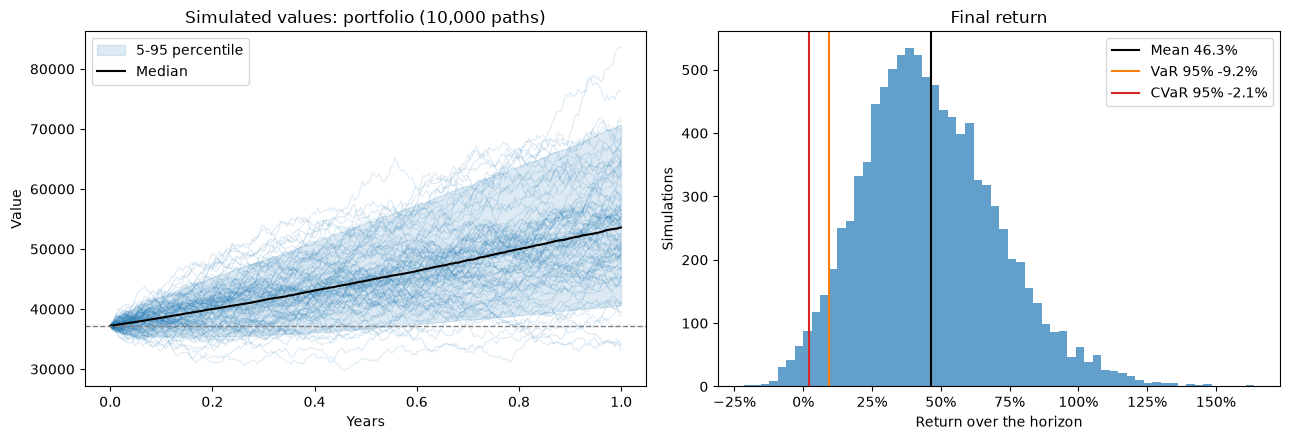

In [18]:
simulation = portfolio.monte_carlo(10_000, years=1, seed=42)
simulation.plot()
pd.Series(simulation.summary()).to_frame("Histórico")

In [19]:
scenarios = {
    "Histórico": simulation,
    "Estrés (3%, 35%)": portfolio.monte_carlo(10_000, years=1, annual_return=0.03, annual_volatility=0.35, seed=42),
    "Solo BTC-USD": portfolio.monte_carlo(10_000, years=1, asset="BTC-USD", seed=42),
}
pd.DataFrame({name: result.summary() for name, result in scenarios.items()})

,Histórico,"Estrés (3%, 35%)",Solo BTC-USD
mean,0.4633,0.0992,1.1938
median,0.4407,0.0303,0.9450
var_95,-0.0923,0.4230,0.1229
cvar_95,-0.0209,0.4974,0.2720
var_99,0.0258,0.5459,0.3689
cvar_99,0.0694,0.5866,0.4441
loss_probability,0.0155,0.4674,0.0838


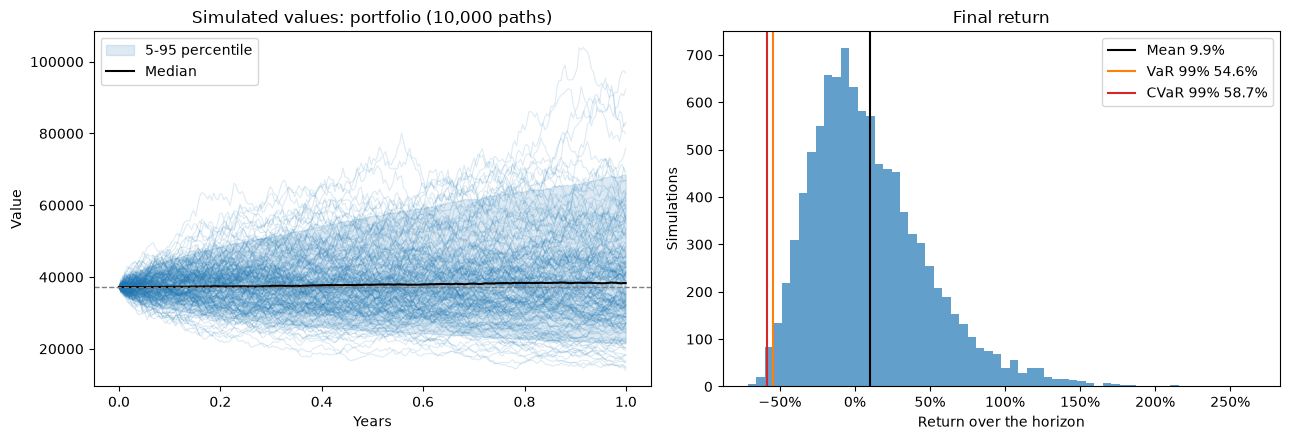

In [20]:
scenarios["Estrés (3%, 35%)"].plot(n_paths=200, level=0.99);

## 9. `report()` en Markdown y `plots_report()`

In [21]:
text = portfolio.report(risk_free=risk_free, monte_carlo=simulation, max_weight=0.3)
display(Markdown(text))

# Portfolio report

From 2023-01-03 to 2025-10-31 · USD · 5 assets

## Summary

| Metric | Value |
|---|---|
| Equity | 37,197.62 |
| Initial capital | 10,000.00 |
| Total return (TWR) | 195.67% |
| Annual expected return | 37.96% |
| Annual volatility | 16.77% |
| Sharpe ratio | 2.04 |
| Max drawdown | -14.20% |
| Cash | 0.00 |
| Cash weight | 0.00% |
| Gross exposure | 100.00% |
| Net exposure | 100.00% |
| Return observations | 710 |

## Assets

| Asset | Type | Weight | Last price | Annual log return | Annual volatility | Max drawdown |
|---|---|---|---|---|---|---|
| AAPL | Stock | 21.05% | 269.37 | 27.76% | 25.92% | -33.36% |
| MSFT | Stock | 23.53% | 513.58 | 28.03% | 23.27% | -23.73% |
| SAN | Stock | 26.27% | 9.90 | 46.69% | 30.66% | -19.89% |
| IEF | Stock | 16.31% | 93.13 | 3.42% | 7.54% | -10.16% |
| BTC-USD | Cryptocurrency | 12.84% | 109,556.16 | 66.57% | 46.70% | -28.14% |

## Monte Carlo

| Monte Carlo: portfolio | Value |
|---|---|
| Simulations | 10,000 |
| Horizon (years) | 1.00 |
| Mean return | 46.33% |
| Median return | 44.07% |
| VaR 95% | -9.23% |
| CVaR 95% | -2.09% |
| VaR 99% | 2.58% |
| CVaR 99% | 6.94% |
| Loss probability | 1.55% |

## Risk warnings

- AAPL: 2 return(s) beyond 5 standard deviations, kept: check that they are real and not data errors.
- MSFT: 1 return(s) beyond 5 standard deviations, kept: check that they are real and not data errors.
- SAN: 1 return(s) beyond 5 standard deviations, kept: check that they are real and not data errors.


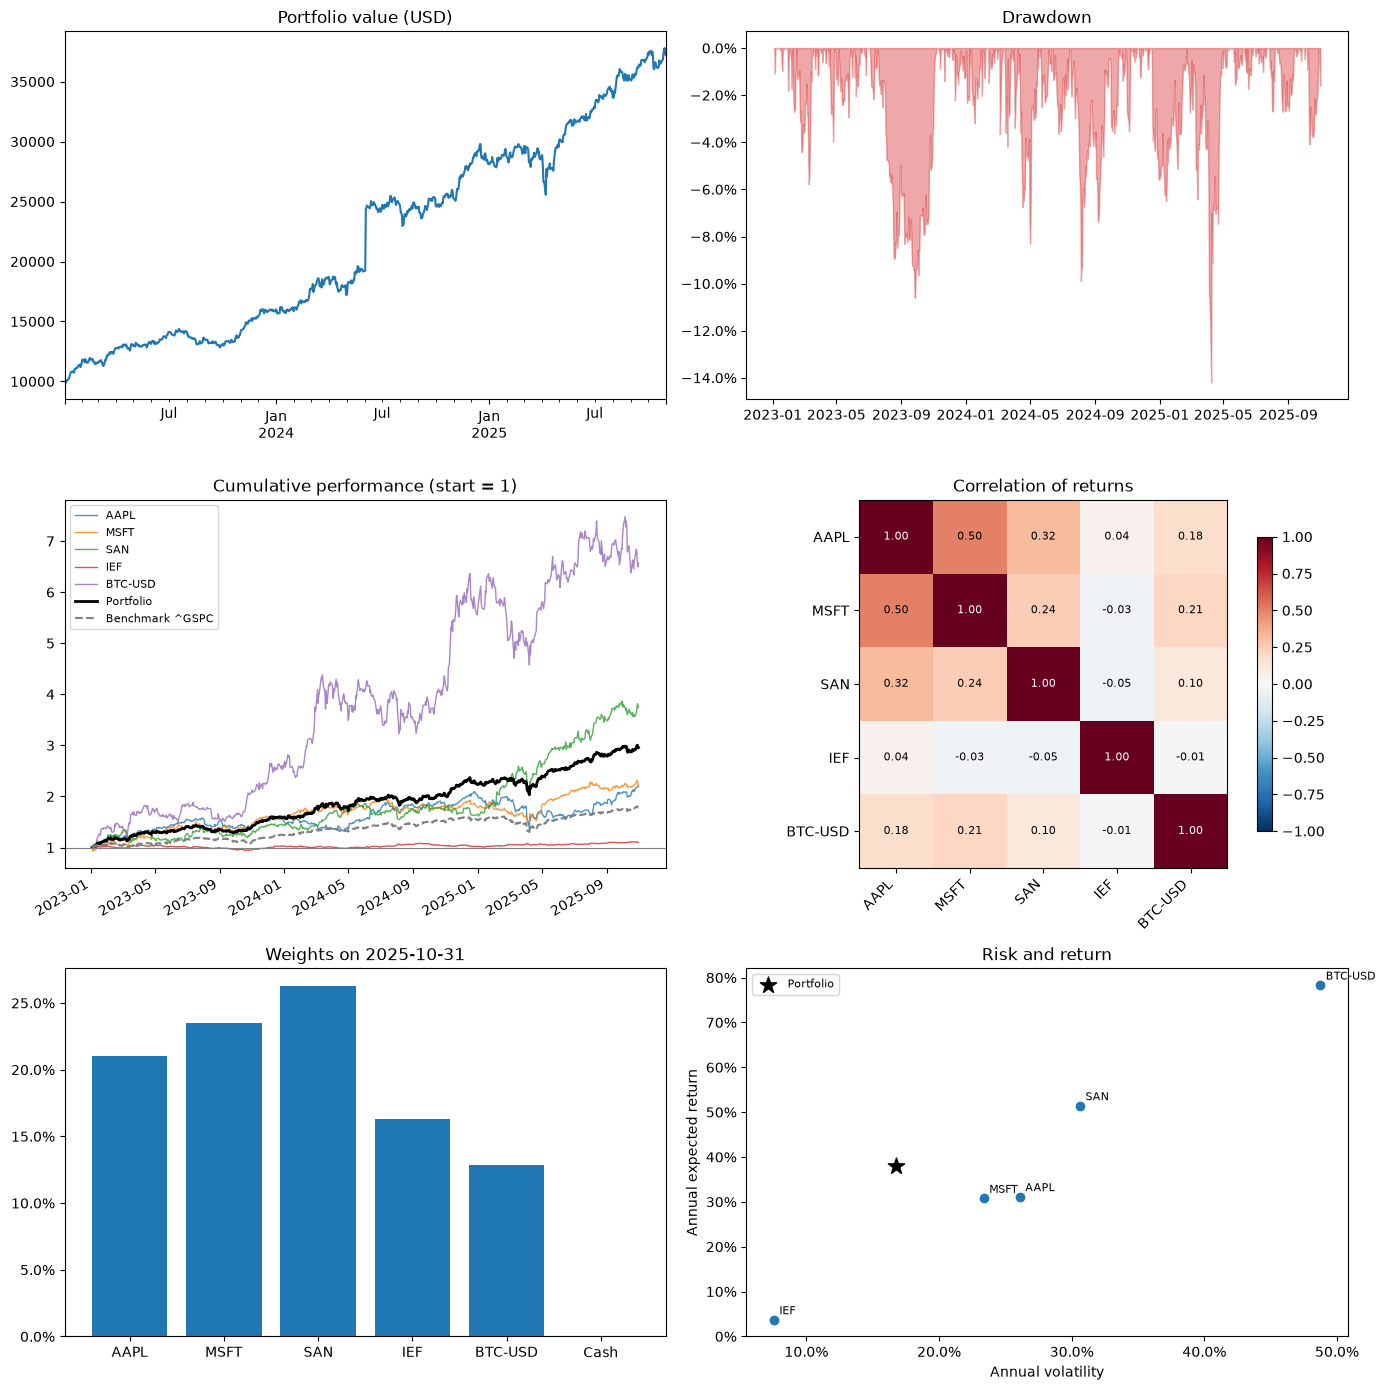

In [22]:
portfolio.plots_report(benchmark=gspc);

## Resumen

- **Diseño en capas**: añadir una API o un análisis no obliga a tocar el resto.
- **Salida estandarizada**: Yahoo, FMP, CoinGecko y 4 bancos centrales producen los mismos objetos.
- **Datos honestos**: no se rellenan precios, los outliers se avisan pero no se borran, y las métricas usan solo fechas observadas.
- **Validación estricta**: errores claros antes que números falsos.